In [1]:
import os
import json
import numpy as np
import librosa
import pandas as pd
#import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import seaborn as sns
from tensorflow.keras import layers, models, Model
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix
from tensorflow.keras.models import load_model

In [2]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

In [3]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

# Load data

In [4]:
X_stem_cqt = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
X_stem_mel = np.load(os.path.join('extracted_segments_features', 'processed_features_mel.npy'))  # or cqt
y_stem = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))
X_mix_mel = np.load("extracted_mix_features/all_mels.npy")
X_mix_cqt = np.load("extracted_mix_features/all_cqts.npy")
y_mix = np.load("extracted_mix_features/all_labels.npy")

# Distributions


Class distribution in the filtered dataset:
  brass: 9085 samples (15.0%)
  electric_bass: 6781 samples (11.2%)
  drum_set: 6300 samples (10.4%)
  piano: 5604 samples (9.2%)
  male_vocals: 4946 samples (8.1%)
  synthesizer: 4790 samples (7.9%)
  other_percussion: 3635 samples (6.0%)
  vocalists: 3180 samples (5.2%)
  acoustic_guitar: 3010 samples (5.0%)
  clean_electric_guitar: 2475 samples (4.1%)
  distorted_electric_guitar: 2452 samples (4.0%)
  violin: 2190 samples (3.6%)
  other_bowed_strings: 1860 samples (3.1%)
  female_singer: 1565 samples (2.6%)
  other_plucked_strings: 1460 samples (2.4%)
  woodwinds: 1383 samples (2.3%)


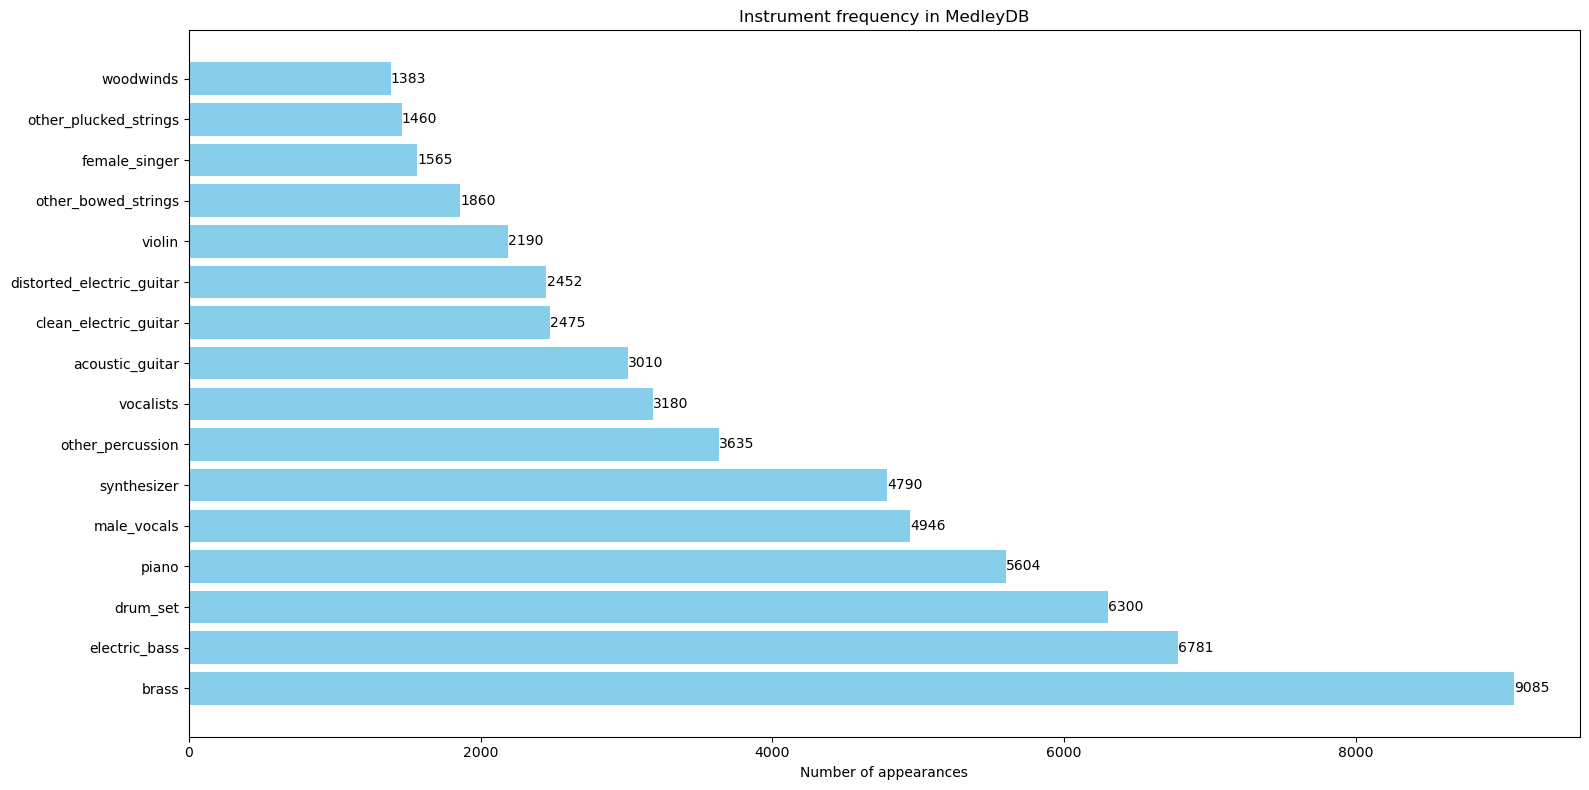


Dataset dimensions:
  Filtered data: (60716, 96, 130)
  Total number of samples: 60716
  Number of categories: 18


In [7]:
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y_stem, return_counts=True)

# Create a dictionary: {category_name: count}
category_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = ordered_labels[idx]
    category_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the filtered dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count / len(y_stem) * 100:.1f}%)")

# Plot histogram
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Dataset summary
print(f"\nDataset dimensions:")
print(f"  Filtered data: {X_stem_mel.shape}")
print(f"  Total number of samples: {len(y_stem)}")
print(f"  Number of categories: {len(ordered_labels)}")


Distribución de clases en el dataset filtrado:
  electric_bass: 4100 muestras (44.8%)
  drum_set: 3884 muestras (42.4%)
  piano: 3395 muestras (37.1%)
  brass: 2597 muestras (28.4%)
  synthesizer: 2402 muestras (26.2%)
  other_percussion: 1767 muestras (19.3%)
  male_vocals: 1760 muestras (19.2%)
  vocalists: 1733 muestras (18.9%)
  distorted_electric_guitar: 1526 muestras (16.7%)
  violin: 1330 muestras (14.5%)
  clean_electric_guitar: 1097 muestras (12.0%)
  female_singer: 851 muestras (9.3%)
  acoustic_guitar: 785 muestras (8.6%)
  other_bowed_strings: 750 muestras (8.2%)
  other_plucked_strings: 750 muestras (8.2%)
  woodwinds: 653 muestras (7.1%)


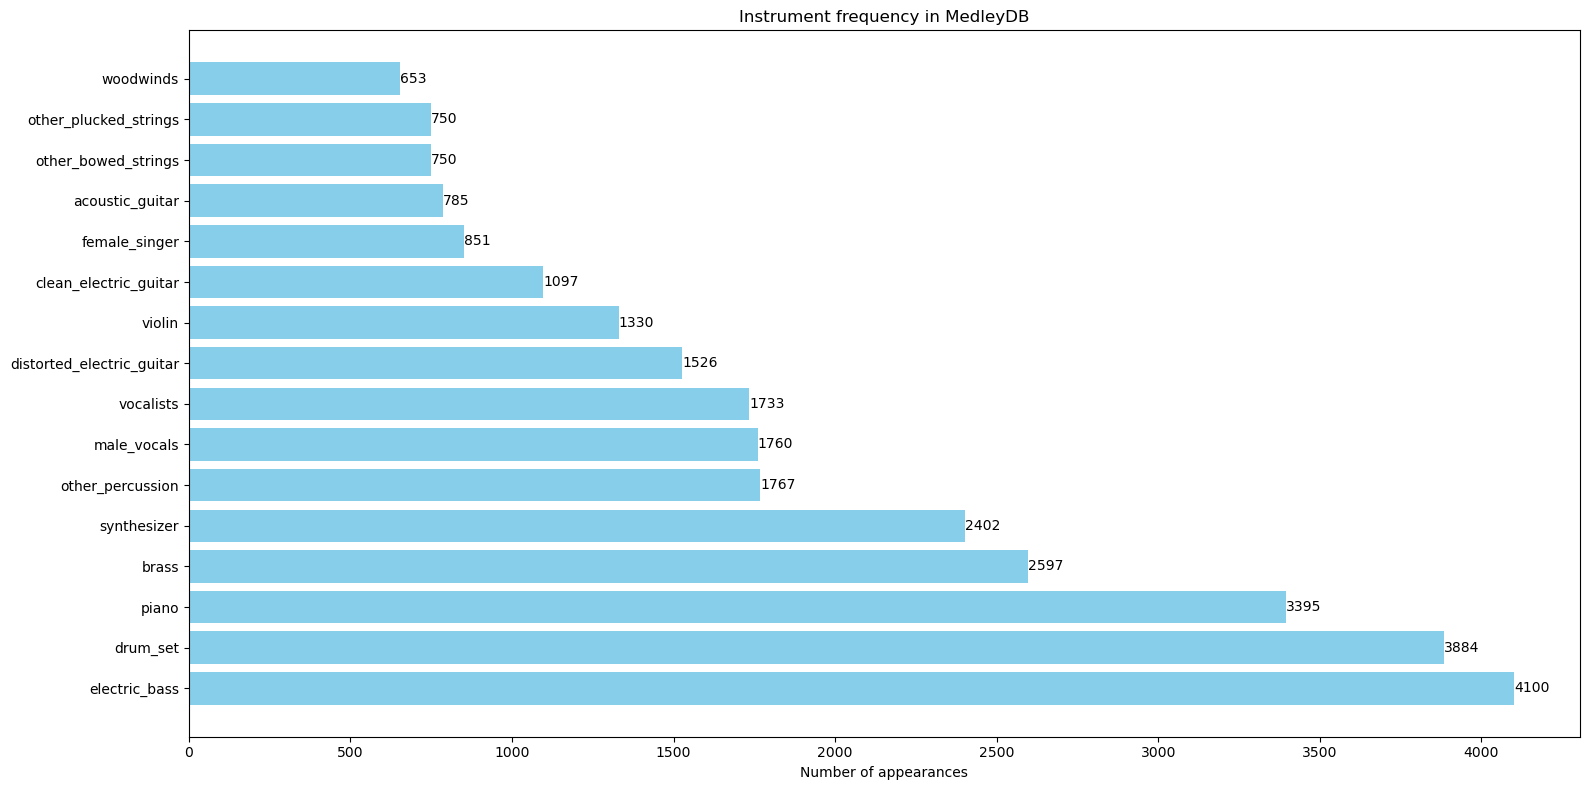


Dimensiones del dataset:
  X: (9154, 96, 130)
  y filtrado (multi-hot): (9154, 16)
  Total de muestras: 9154
  Número de categorías actuales: 18


In [8]:
# Sumar cuántas veces aparece cada clase (suma por columnas)
class_counts = np.sum(y_mix, axis=0)

# Crear diccionario {nombre_categoria: cantidad}
category_counts = {label: int(count) for label, count in zip(ordered_labels, class_counts)}

# Mostrar la distribución
print("\nDistribución de clases en el dataset filtrado:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} muestras ({count / len(y_mix) * 100:.1f}%)")

# Graficar histograma
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Resumen general
print(f"\nDimensiones del dataset:")
print(f"  X: {X_mix_cqt.shape}")
print(f"  y filtrado (multi-hot): {y_mix.shape}")
print(f"  Total de muestras: {len(y_mix)}")
print(f"  Número de categorías actuales: {len(ordered_labels)}")

# Normalize


In [9]:
mean_cqt = np.mean(X_mix_cqt)
std_cqt = np.std(X_mix_cqt)

mean_mel = np.mean(X_mix_mel)
std_mel = np.std(X_mix_mel)

X_stem_cqt = (X_stem_cqt - mean_cqt) / (std_cqt + 1e-6)
X_stem_mel = (X_stem_mel - mean_mel) / (std_mel + 1e-6)

X_mix_cqt = (X_mix_cqt - mean_cqt) / (std_cqt + 1e-6)
X_mix_mel = (X_mix_mel - mean_mel) / (std_mel + 1e-6)

# Splitting data

In [10]:
'''
# Split into train, validation, and test sets for stem cqt
X_temp, X_test_stem_cqt, y_temp, y_test_stem = train_test_split(
    X_stem_cqt, y_stem, test_size=0.1, random_state=42
)
X_train_stem_cqt, X_val_stem_cqt, y_train_stem, y_val_stem = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Split into train, validation, and test sets for mix cqt
X_temp, X_test_mix_cqt, y_temp, y_test_mix = train_test_split(
    X_mix_cqt, y_mix, test_size=0.1, random_state=42
)
X_train_mix_cqt, X_val_mix_cqt, y_train_mix, y_val_mix = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)
'''

# Split into train, validation, and test sets for stem mel
X_temp, X_test_stem_mel, y_temp, y_test_stem = train_test_split(
    X_stem_mel, y_stem, test_size=0.1, random_state=42
)
X_train_stem_mel, X_val_stem_mel, y_train_stem, y_val_stem = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Split into train, validation, and test sets for mix mel
X_temp, X_test_mix_mel, y_temp, y_test_mix = train_test_split(
    X_mix_cqt, y_mix, test_size=0.1, random_state=42
)
X_train_mix_mel, X_val_mix_mel, y_train_mix, y_val_mix = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Model 1

In [11]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model_phase1 = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax')  # softmax for stems (single label)
])

model_phase1.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])
model_phase1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128       
 hNormalization)                                                 
                                                        

In [ ]:
# Callbacks for phase 1
callbacks_phase1 = [
    CSVLogger('training_model_hybrid_stems.log', append=False),
    EarlyStopping(monitor='val_loss', patience=25),
    ModelCheckpoint('best_model_hybrid_stems.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

# Train on stems
model_phase1.fit(
    X_train_stem_mel, y_train_stem,
    validation_data=(X_val_stem_mel, y_val_stem),
    epochs=200,
    batch_size=32,
    callbacks=callbacks_phase1
)

Epoch 1/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.4843 - loss: 1.6108
Epoch 1: val_accuracy improved from -inf to 0.74616, saving model to best_model_stems.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 196s 133ms/step - accuracy: 0.4844 - loss: 1.6105 - val_accuracy: 0.7462 - val_loss: 0.7508
Epoch 2/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.7647 - loss: 0.7049
Epoch 2: val_accuracy improved from 0.74616 to 0.78568, saving model to best_model_stems.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 218s 153ms/step - accuracy: 0.7647 - loss: 0.7048 - val_accuracy: 0.7857 - val_loss: 0.7546
Epoch 3/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.8380 - loss: 0.4889
Epoch 3: val_accuracy improved from 0.78568 to 0.84859, saving model to best_model_stems.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 203s 143ms/step - accuracy: 0.8380 - loss: 0.4889 - val_accuracy: 0.8486 - val_loss: 0.4662
Epoch 4/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.8668 - loss: 0.4006
Epoch 4: val_accuracy did not improve from 0.84859
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 252s 177ms/step - accuracy: 0.8668 - loss: 0.4006 - val_accuracy: 0.8002 - val_loss: 0.6516
Epoch 5/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - accuracy: 0.8875 - loss: 0.3406
Epoch 5: val_accuracy improved from 0.84859 to 0.86155, saving model to best_model_stems.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 379s 266ms/step - accuracy: 0.8875 - loss: 0.3406 - val_accuracy: 0.8616 - val_loss: 0.4445
Epoch 6/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.8969 - loss: 0.3127
Epoch 6: val_accuracy improved from 0.86155 to 0.87231, saving model to best_model_stems.h5


...

1423/1423 ━━━━━━━━━━━━━━━━━━━━ 359s 252ms/step - accuracy: 0.9214 - loss: 0.2290 - val_accuracy: 0.9171 - val_loss: 0.2534
Epoch 12/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.9287 - loss: 0.2052
Epoch 12: val_accuracy did not improve from 0.91711
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 364s 256ms/step - accuracy: 0.9287 - loss: 0.2052 - val_accuracy: 0.7852 - val_loss: 0.9732
Epoch 13/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.9289 - loss: 0.2099
Epoch 13: val_accuracy did not improve from 0.91711
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 190s 133ms/step - accuracy: 0.9289 - loss: 0.2099 - val_accuracy: 0.9108 - val_loss: 0.2675
Epoch 14/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.9322 - loss: 0.1950
Epoch 14: val_accuracy did not improve from 0.91711
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 187s 132ms/step - accuracy: 0.9322 - loss: 0.1950 - val_accuracy: 0.7131 - val_loss: 1.1801
Epoch 15/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.9334

1423/1423 ━━━━━━━━━━━━━━━━━━━━ 189s 133ms/step - accuracy: 0.9439 - loss: 0.1586 - val_accuracy: 0.9201 - val_loss: 0.2433
Epoch 22/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.9425 - loss: 0.1630
Epoch 22: val_accuracy did not improve from 0.92007
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 195s 128ms/step - accuracy: 0.9425 - loss: 0.1630 - val_accuracy: 0.9140 - val_loss: 0.2906
Epoch 23/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9500 - loss: 0.1430
Epoch 23: val_accuracy did not improve from 0.92007
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 1870s 1s/step - accuracy: 0.9500 - loss: 0.1430 - val_accuracy: 0.8978 - val_loss: 0.3502
Epoch 24/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 822ms/step - accuracy: 0.9486 - loss: 0.1448
Epoch 24: val_accuracy improved from 0.92007 to 0.93808, saving model to best_model_stems.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 1187s 832ms/step - accuracy: 0.9486 - loss: 0.1448 - val_accuracy: 0.9381 - val_loss: 0.1825
Epoch 25/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.9470 - loss: 0.1474
Epoch 25: val_accuracy did not improve from 0.93808
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 396s 278ms/step - accuracy: 0.9470 - loss: 0.1474 - val_accuracy: 0.9286 - val_loss: 0.2103
Epoch 26/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9505 - loss: 0.1388
Epoch 26: val_accuracy did not improve from 0.93808
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 396s 279ms/step - accuracy: 0.9505 - loss: 0.1388 - val_accuracy: 0.9184 - val_loss: 0.2717
Epoch 27/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.9542 - loss: 0.1326
Epoch 27: val_accuracy did not improve from 0.93808
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 415s 292ms/step - accuracy: 0.9542 - loss: 0.1326 - val_accuracy: 0.9212 - val_loss: 0.2495
Epoch 28/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.951

1423/1423 ━━━━━━━━━━━━━━━━━━━━ 402s 283ms/step - accuracy: 0.9532 - loss: 0.1352 - val_accuracy: 0.9499 - val_loss: 0.1434
Epoch 30/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.9547 - loss: 0.1303
Epoch 30: val_accuracy did not improve from 0.94993
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 334s 234ms/step - accuracy: 0.9547 - loss: 0.1303 - val_accuracy: 0.8620 - val_loss: 0.5501
Epoch 31/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.9566 - loss: 0.1263
Epoch 31: val_accuracy did not improve from 0.94993
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 330s 232ms/step - accuracy: 0.9566 - loss: 0.1263 - val_accuracy: 0.9393 - val_loss: 0.1868
Epoch 32/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.9569 - loss: 0.1228
Epoch 32: val_accuracy did not improve from 0.94993
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 194s 136ms/step - accuracy: 0.9569 - loss: 0.1228 - val_accuracy: 0.9381 - val_loss: 0.1940
Epoch 33/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.9559

KeyboardInterrupt: 

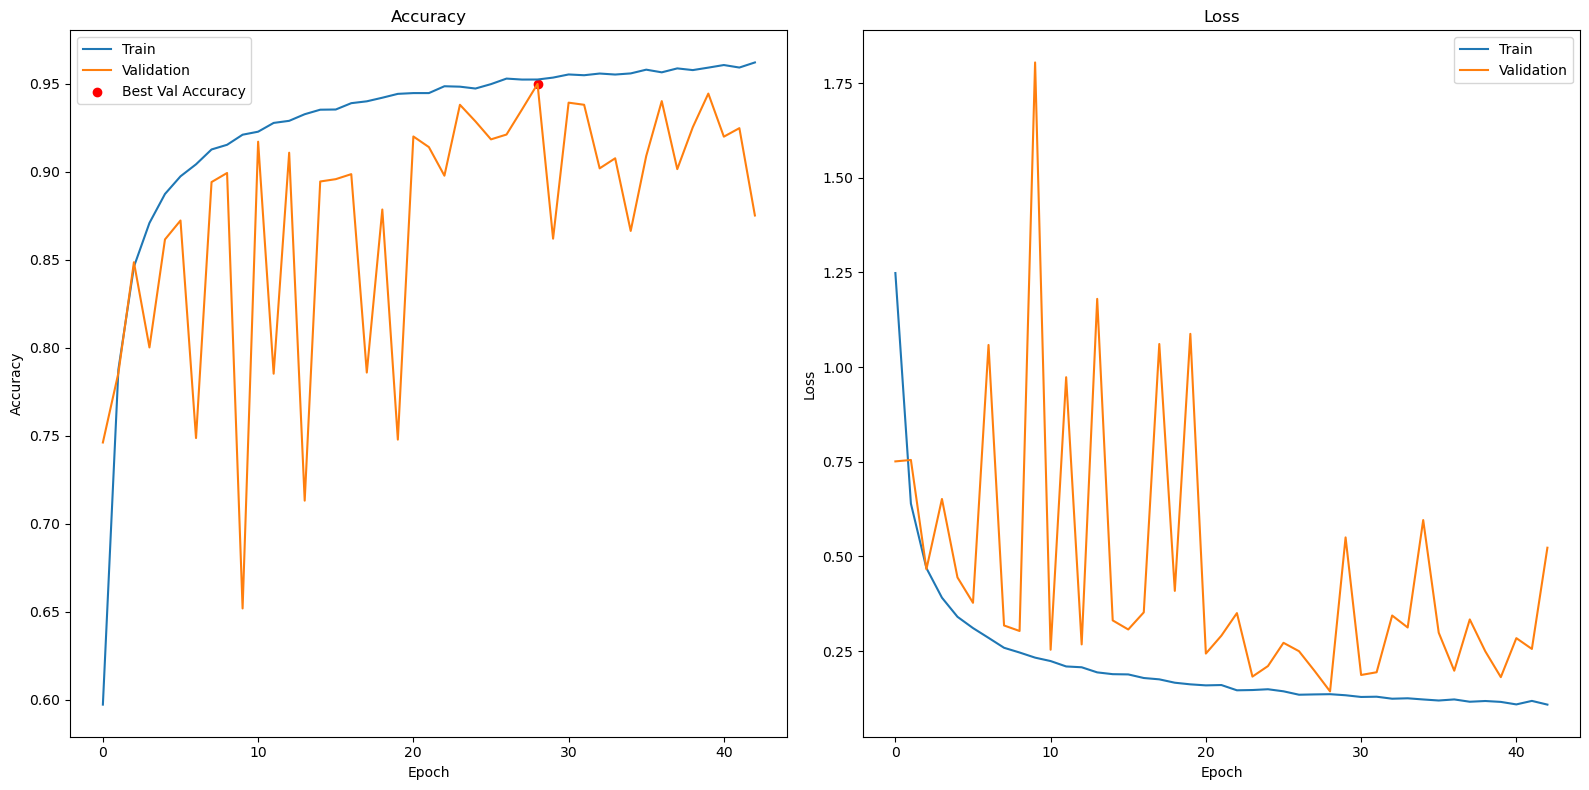

In [ ]:
# History plot
log_df = pd.read_csv('training_model_hybrid_stems.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

# Model 2

In [ ]:
model_best_stems = load_model('best_model_hybrid_stems.h5')

# Extraer capas y reconstruir funcionalmente
inputs = layers.Input(shape=(96, 130, 1))
x = model_best_stems.layers[0](inputs)
for layer in model_best_stems.layers[1:-1]:  # Excluye la última:  Dense(softmax)
    x = layer(x)

# x = layers.Dense(64, activation='relu')(x)
#x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='sigmoid', name='output')(x)

model_phase2 = Model(inputs=inputs, outputs=outputs)


# === FREEZE CONVOLUTIONAL LAYERS ===

# Option: freeze first N Conv2D layers
N = 0  # Change this value (0–3) to freeze desired number of conv layers
conv_layers_frozen = 0
for layer in model_phase2.layers:
    if isinstance(layer, layers.Conv2D):
        if conv_layers_frozen < N:
            layer.trainable = False
            conv_layers_frozen += 1

# Compile for multilabel
model_phase2.compile(optimizer='adam',
                     loss='binary_crossentropy',
                     metrics=['binary_accuracy'])
model_phase2.summary()

Model: "functional_97"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 96, 130, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 96, 130, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 96, 130, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 48, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,944 (113.06 KB)

 Trainable params: 28,720 (112.19 KB)

 Non-trainable params: 224 (896.00 B)

In [ ]:
# Callbacks for phase 2
callbacks_phase2 = [
    CSVLogger('training_model_hybrid_mix.log', append=False),
    EarlyStopping(monitor='val_loss', patience=50),
    ModelCheckpoint('best_model_hybrid_mix.h5', monitor='val_binary_accuracy', save_best_only=True, verbose=1)
]

# Train on mixes
history = model_phase2.fit(
    X_train_mix_mel, y_train_mix,
    validation_data=(X_val_mix_mel, y_val_mix),
    epochs=300,
    batch_size=32,
    callbacks=callbacks_phase2
)

Epoch 1/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - binary_accuracy: 0.7166 - loss: 0.5625
Epoch 1: val_binary_accuracy improved from -inf to 0.80631, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 98s 275ms/step - binary_accuracy: 0.7169 - loss: 0.5621 - val_binary_accuracy: 0.8063 - val_loss: 1.1419
Epoch 2/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - binary_accuracy: 0.8476 - loss: 0.3587
Epoch 2: val_binary_accuracy improved from 0.80631 to 0.82133, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 57s 263ms/step - binary_accuracy: 0.8477 - loss: 0.3586 - val_binary_accuracy: 0.8213 - val_loss: 0.6769
Epoch 3/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - binary_accuracy: 0.8721 - loss: 0.3018
Epoch 3: val_binary_accuracy improved from 0.82133 to 0.85333, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 116s 423ms/step - binary_accuracy: 0.8721 - loss: 0.3018 - val_binary_accuracy: 0.8533 - val_loss: 0.3495
Epoch 4/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - binary_accuracy: 0.8854 - loss: 0.2714
Epoch 4: val_binary_accuracy improved from 0.85333 to 0.87491, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 102s 472ms/step - binary_accuracy: 0.8854 - loss: 0.2714 - val_binary_accuracy: 0.8749 - val_loss: 0.3002
Epoch 5/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step - binary_accuracy: 0.8956 - loss: 0.2486
Epoch 5: val_binary_accuracy improved from 0.87491 to 0.88884, saving model to best_model_mix.h5


...

215/215 ━━━━━━━━━━━━━━━━━━━━ 57s 263ms/step - binary_accuracy: 0.9473 - loss: 0.1337 - val_binary_accuracy: 0.9432 - val_loss: 0.1435
Epoch 20/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - binary_accuracy: 0.9478 - loss: 0.1298
Epoch 20: val_binary_accuracy did not improve from 0.94324
215/215 ━━━━━━━━━━━━━━━━━━━━ 55s 257ms/step - binary_accuracy: 0.9478 - loss: 0.1298 - val_binary_accuracy: 0.9422 - val_loss: 0.1431
Epoch 21/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step - binary_accuracy: 0.9488 - loss: 0.1266
Epoch 21: val_binary_accuracy did not improve from 0.94324
215/215 ━━━━━━━━━━━━━━━━━━━━ 57s 266ms/step - binary_accuracy: 0.9488 - loss: 0.1266 - val_binary_accuracy: 0.9420 - val_loss: 0.1480
Epoch 22/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step - binary_accuracy: 0.9498 - loss: 0.1247
Epoch 22: val_binary_accuracy did not improve from 0.94324
215/215 ━━━━━━━━━━━━━━━━━━━━ 59s 275ms/step - binary_accuracy: 0.9498 - loss: 0.1247 - val_binary_accuracy: 0.9420 - val_loss: 0.1

215/215 ━━━━━━━━━━━━━━━━━━━━ 59s 274ms/step - binary_accuracy: 0.9519 - loss: 0.1194 - val_binary_accuracy: 0.9488 - val_loss: 0.1325
Epoch 26/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - binary_accuracy: 0.9548 - loss: 0.1140
Epoch 26: val_binary_accuracy improved from 0.94883 to 0.95330, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 58s 271ms/step - binary_accuracy: 0.9548 - loss: 0.1140 - val_binary_accuracy: 0.9533 - val_loss: 0.1209
Epoch 27/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - binary_accuracy: 0.9545 - loss: 0.1134
Epoch 27: val_binary_accuracy did not improve from 0.95330
215/215 ━━━━━━━━━━━━━━━━━━━━ 57s 263ms/step - binary_accuracy: 0.9545 - loss: 0.1134 - val_binary_accuracy: 0.9469 - val_loss: 0.1372
Epoch 28/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - binary_accuracy: 0.9562 - loss: 0.1104
Epoch 28: val_binary_accuracy did not improve from 0.95330
215/215 ━━━━━━━━━━━━━━━━━━━━ 59s 273ms/step - binary_accuracy: 0.9562 - loss: 0.1104 - val_binary_accuracy: 0.9466 - val_loss: 0.1363
Epoch 29/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - binary_accuracy: 0.9558 - loss: 0.1118
Epoch 29: val_binary_accuracy did not improve from 0.95330
215/215 ━━━━━━━━━━━━━━━━━━━━ 79s 260ms/step - binary_accuracy: 0.9558 - loss: 0.1118 - val_binary_accuracy: 0.9514 - val_loss: 0.1

215/215 ━━━━━━━━━━━━━━━━━━━━ 51s 237ms/step - binary_accuracy: 0.9597 - loss: 0.1014 - val_binary_accuracy: 0.9533 - val_loss: 0.1196
Epoch 35/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - binary_accuracy: 0.9602 - loss: 0.0999
Epoch 35: val_binary_accuracy did not improve from 0.95334
215/215 ━━━━━━━━━━━━━━━━━━━━ 51s 239ms/step - binary_accuracy: 0.9601 - loss: 0.0999 - val_binary_accuracy: 0.9504 - val_loss: 0.1342
Epoch 36/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - binary_accuracy: 0.9604 - loss: 0.1007
Epoch 36: val_binary_accuracy did not improve from 0.95334
215/215 ━━━━━━━━━━━━━━━━━━━━ 51s 239ms/step - binary_accuracy: 0.9604 - loss: 0.1007 - val_binary_accuracy: 0.9531 - val_loss: 0.1230
Epoch 37/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - binary_accuracy: 0.9605 - loss: 0.0989
Epoch 37: val_binary_accuracy did not improve from 0.95334
215/215 ━━━━━━━━━━━━━━━━━━━━ 51s 236ms/step - binary_accuracy: 0.9605 - loss: 0.0989 - val_binary_accuracy: 0.9453 - val_loss: 0.1

KeyboardInterrupt: 

In [ ]:
# History plot
log_df = pd.read_csv('training_model_hybrid_mix.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Confusion matrix for validation and test sets
model_phase2.load_weights('best_model_hybrid_mix.h5')

from sklearn.metrics import multilabel_confusion_matrix

# Predict probabilities
y_val_pred_prob = model_phase2.predict(X_val_mix_mel)
y_test_pred_prob = model_phase2.predict(X_test_mix_mel)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val_mix, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test_mix, y_test_pred)

# Model 3

In [12]:
model_best_stems = load_model('best_model_hybrid_stems.h5')

# Extraer capas y reconstruir funcionalmente
inputs = layers.Input(shape=(96, 130, 1))
x = model_best_stems.layers[0](inputs)
for layer in model_best_stems.layers[1:-1]:  # Excluye la última:  Dense(softmax)
    x = layer(x)

# x = layers.Dense(64, activation='relu')(x)
#x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='sigmoid', name='output')(x)

model_phase3 = Model(inputs=inputs, outputs=outputs)


# === FREEZE CONVOLUTIONAL LAYERS ===

# Option: freeze first N Conv2D layers
N = 0  # Change this value (0–3) to freeze desired number of conv layers
conv_layers_frozen = 0
for layer in model_phase3.layers:
    if isinstance(layer, layers.Conv2D):
        if conv_layers_frozen < N:
            layer.trainable = False
            conv_layers_frozen += 1

# Compile for multilabel
model_phase3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        'binary_accuracy'
    ]
)
model_phase3.summary()

OSError: No file or directory found at best_model_hybrid_stems.h5

In [ ]:
# Callbacks for phase 3
callbacks_phase3 = [
    CSVLogger('training_model_hybrid_mix_2.log', append=False),
    EarlyStopping(monitor='val_loss', patience=50),
    ModelCheckpoint('best_model_hybrid_mix_2.h5', monitor='val_binary_accuracy', save_best_only=True, verbose=1)
]

# Train on mixes
history = model_phase3.fit(
    X_train_mix_mel, y_train_mix,
    validation_data=(X_val_mix_mel, y_val_mix),
    epochs=300,
    batch_size=32,
    callbacks=callbacks_phase2
)

In [ ]:
# History plot
log_df = pd.read_csv('training_model_hybrid_mix_2.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()